# Processing MESACLIP data - atmosphere monthly, single ensembles

* **Description**: Reads in MESACLIP historical and crops to just the Arctic Amplification/temperature
* **Creator**: Alice DuVivier
* **Date**: December 2025

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
from glob import glob
from datetime import datetime
import xesmf as xe
import matplotlib.pyplot as plt
import scipy.sparse as sps

import dask
from distributed import Client
from ncar_jobqueue import NCARCluster

## Spin up DASK cluster

In [2]:
# Create our NCAR Cluster - which uses PBSCluster under the hood
cluster = NCARCluster(walltime='2:00:00', cores=1, processes=1, memory='100 GB', 
                      resource_spec='select=1:ncpus=1:mem=100GB',interface='ext')

# Spin up 32 workers
cluster.scale(32)

# Assign the cluster to our Client
client = Client(cluster)

/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/dask_jobqueue/core.py:255: FutureWarning: job_extra has been renamed to job_extra_directives. You are still using it (even if only set to []; please also check config files). If you did not set job_extra_directives yet, job_extra will be respected for now, but it will be removed in a future release. If you already set job_extra_directives, job_extra is ignored and you can remove it.
  warnings.warn(warn, FutureWarning)
/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/dask_jobqueue/core.py:274: FutureWarning: env_extra has been renamed to job_script_prologue. You are still using it (even if only set to []; please also check config files). If you did not set job_script_prologue yet, env_extra will be respected for now, but it will be removed in a future release. If you already set job_script_prologue, env_extra is ignored and you can remove it.
  warnings.warn(warn, FutureWarning)
/glade/u/apps/opt/con

In [3]:
client
# cluster.close()

Connection method: Cluster object,Cluster type: dask_jobqueue.PBSCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/duvivier/PBS/proxy/36735/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/duvivier/PBS/proxy/36735/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://128.117.208.176:42753,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/duvivier/PBS/proxy/36735/status,Total threads: 0
Started: Just now,Total memory: 0 B


## Set MESACLIP ensemble information

In [14]:
# RCP 8.5
path_base = '/gdex/data/d651009/'
case_base = 'b.e13.BRCP85C5.ne120_t12.cesm-ihesp-'
# list 10 members of MESACLIP - last one is the first and named differently
ens_mems = ['sehires38-2006-2100.001', 'hires1.0.30-2006-2100.002', 
            'hires1.0.31-2006-2100.003', 'hires1.0.44-2006-2100.004', 
            'hires1.0.44-2006-2100.005', 'hires1.0.46-2006-2100.006', 
            'hires1.0.46-2006-2100.007', 'hires1.0.46-2006-2100.008',
            'hires1.0.46-2006-2100.009', 'hires1.0.46-2006-2100.010']
nens = len(ens_mems)

## Load in ATMOSPHERIC Data

In [5]:
# Choose variable to load

var_in = 'TREFHT'

In [157]:
# Choose ensemble to load
n = 9
ens_in = ens_mems[n]
print(ens_in)

hires1.0.46-2006-2100.010


In [158]:
%%time

print('loading data for member: '+ens_in)

# set case
case = case_base + ens_in
# set data directory
path = path_base+case+'/atm/proc/tseries/month_1'
# get list of files
files = sorted(glob(f'{path}/{case}.cam.h0.{var_in}.??????-??????.nc'))       
# load files
ds_tmp = xr.open_mfdataset(files, data_vars="minimal", coords='minimal', compat="override", parallel=True, 
                           concat_dim="time", combine='nested', decode_times=True)
# take an average over the time bounds to get the right time dimension
ds_tmp["time"] = ds_tmp.time_bnds.compute().mean(dim="nbnd")


loading data for member: hires1.0.46-2006-2100.010
CPU times: user 1.18 s, sys: 32 ms, total: 1.21 s
Wall time: 1.84 s


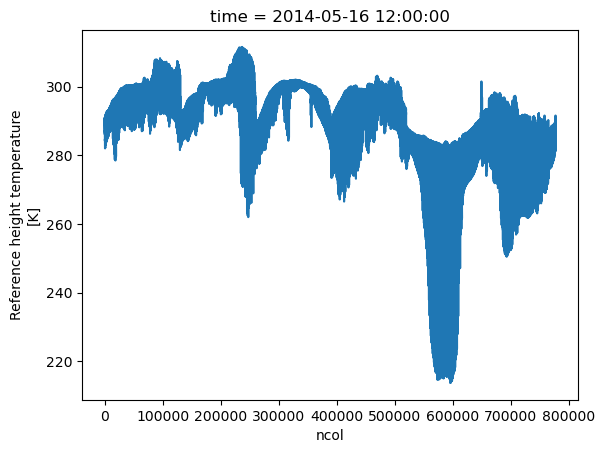

In [159]:
# check data
ds_tmp.TREFHT.isel(time=100).plot()

### Remap to a regular grid

In [160]:
#wgtfile = '/glade/work/fredc/Regrid_Maps/ne120np4_pentagons_to_latlon_0.25x0.25_0E_bilinear_20210903.nc'
wgtfile = '/glade/work/fredc/Regrid_Maps/ne120np4_pentagons_to_latlon_0.25x0.25_0E_conserve_20200309.nc'
dsw = xr.open_dataset(wgtfile)

In [161]:
def remap_camse(ds, dsw, varlst=[]):
    dso = xr.full_like(ds.drop_dims('ncol'), np.nan)
    lonb = dsw.xc_b.values.reshape([dsw.dst_grid_dims[1].values, dsw.dst_grid_dims[0].values])
    latb = dsw.yc_b.values.reshape([dsw.dst_grid_dims[1].values, dsw.dst_grid_dims[0].values])
    weights = sps.coo_matrix((dsw.S, (dsw.row-1, dsw.col-1)), shape=[dsw.sizes['n_b'], dsw.sizes['n_a']])
    if not varlst:
        for varname in list(ds):
            if 'ncol' in(ds[varname].dims):
                varlst.append(varname)
        if 'lon' in varlst: varlst.remove('lon')
        if 'lat' in varlst: varlst.remove('lat')
        if 'area' in varlst: varlst.remove('area')
    for varname in varlst:
        shape = ds[varname].shape
        invar_flat = ds[varname].values.reshape(-1, shape[-1])
        remapped_flat = weights.dot(invar_flat.T).T
        remapped = remapped_flat.reshape([*shape[0:-1], dsw.dst_grid_dims[1].values, dsw.dst_grid_dims[0].values])
        dimlst = list(ds[varname].dims[0:-1])
        dims={}
        coords={}
        for it in dimlst:
            dims[it] = dso.sizes[it]
            coords[it] = dso.coords[it]
        dims['lat'] = int(dsw.dst_grid_dims[1])
        dims['lon'] = int(dsw.dst_grid_dims[0])
        coords['lat'] = latb[:,0]
        coords['lon'] = lonb[0,:]
        remapped = xr.DataArray(remapped, coords=coords, dims=dims, attrs=ds[varname].attrs)
        dso = xr.merge([dso, remapped.to_dataset(name=varname)])
    varlst.clear() #not sure why this is needed but varlst was not cleared and it created issues with successive call to remap_camse
    return dso

In [162]:
%%time
ds = remap_camse(ds_tmp,dsw)

/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/numpy/core/numeric.py:407: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')


CPU times: user 9.11 s, sys: 8.86 s, total: 18 s
Wall time: 30.7 s


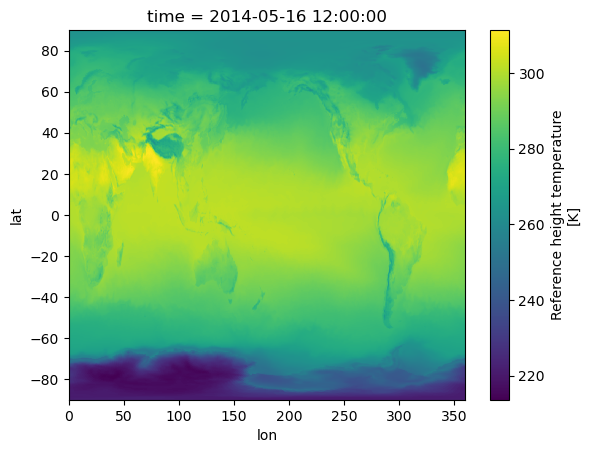

In [163]:
# check data
ds.TREFHT.isel(time=100).plot()

## Subset file to Arctic Only
- ">50N"

In [164]:
ds.lat[560:720]

<xarray.DataArray 'lat' (lat: 160)>
array([50.125, 50.375, 50.625, 50.875, 51.125, 51.375, 51.625, 51.875, 52.125,
       52.375, 52.625, 52.875, 53.125, 53.375, 53.625, 53.875, 54.125, 54.375,
       54.625, 54.875, 55.125, 55.375, 55.625, 55.875, 56.125, 56.375, 56.625,
       56.875, 57.125, 57.375, 57.625, 57.875, 58.125, 58.375, 58.625, 58.875,
       59.125, 59.375, 59.625, 59.875, 60.125, 60.375, 60.625, 60.875, 61.125,
       61.375, 61.625, 61.875, 62.125, 62.375, 62.625, 62.875, 63.125, 63.375,
       63.625, 63.875, 64.125, 64.375, 64.625, 64.875, 65.125, 65.375, 65.625,
       65.875, 66.125, 66.375, 66.625, 66.875, 67.125, 67.375, 67.625, 67.875,
       68.125, 68.375, 68.625, 68.875, 69.125, 69.375, 69.625, 69.875, 70.125,
       70.375, 70.625, 70.875, 71.125, 71.375, 71.625, 71.875, 72.125, 72.375,
       72.625, 72.875, 73.125, 73.375, 73.625, 73.875, 74.125, 74.375, 74.625,
       74.875, 75.125, 75.375, 75.625, 75.875, 76.125, 76.375, 76.625, 76.875,
       77.125, 77.375, 77.625, 77.875, 78.125, 78.375, 78.625, 78.875, 79.125,
       79.375, 79.625, 79.875, 80.125, 80.375, 80.625, 80.875, 81.125, 81.375,
       81.625, 81.875, 82.125, 82.375, 82.625, 82.875, 83.125, 83.375, 83.625,
       83.875, 84.125, 84.375, 84.625, 84.875, 85.125, 85.375, 85.625, 85.875,
       86.125, 86.375, 86.625, 86.875, 87.125, 87.375, 87.625, 87.875, 88.125,
       88.375, 88.625, 88.875, 89.125, 89.375, 89.625, 89.875])
Coordinates:
  * lat      (lat) float64 50.12 50.38 50.62 50.88 ... 89.12 89.38 89.62 89.88

In [165]:
ds_sub = ds.isel(lat=slice(560,720))

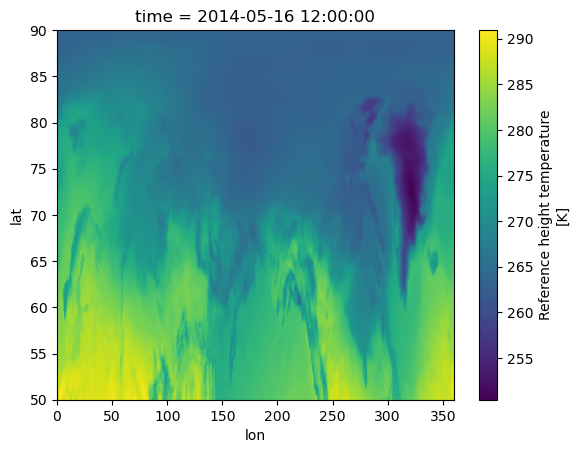

In [166]:
# check data
ds_sub.TREFHT.isel(time=100).plot()

## Export and save the file
- NOTE: YOU MUST MANUALLY ENTER THE VARIABLE NAME BELOW

In [167]:
# set output path and names
path_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/mesaclip_all_arctic/monthly/TREFHT/'

# set output file name
nn = n+1
if nn < 10:
    ensnum = '00'+str(nn)
elif nn >= 10:
    ensnum = '010'

file_out = 'MESACLIP_RCP8.5_'+ensnum+'_2015-2099_'+var_in+'_arctic_monthly.nc'
fout = path_out + file_out
print(fout)

/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/mesaclip_all_arctic/monthly/TREFHT/MESACLIP_RCP8.5_010_2015-2099_TREFHT_arctic_monthly.nc


In [168]:
ds_out = xr.Dataset()

ds_out['TREFHT'] = ds_sub.TREFHT

# change the attributes
ds_out.attrs['author'] = 'Alice DuVivier'
ds_out.attrs['date_processed'] = datetime.now().strftime('%Y-%m-%d')
ds_out.attrs['contents'] = f'Subset of RCP6.0 MESACLIP Data'

ds_out

<xarray.Dataset>
Dimensions:  (time: 1140, lat: 160, lon: 1440)
Coordinates:
  * time     (time) object 2006-01-16 12:00:00 ... 2100-12-16 12:00:00
  * lat      (lat) float64 50.12 50.38 50.62 50.88 ... 89.12 89.38 89.62 89.88
  * lon      (lon) float64 0.125 0.375 0.625 0.875 ... 359.1 359.4 359.6 359.9
Data variables:
    TREFHT   (time, lat, lon) float64 280.7 280.7 280.5 ... 274.5 274.5 274.5
Attributes:
    author:          Alice DuVivier
    date_processed:  2025-12-12
    contents:        Subset of RCP6.0 MESACLIP Data

In [169]:
# Print the dimensions
print("Dimensions:")
for dim in ds_out.dims:
    print(f"\t{dim}: {ds_out[dim].values.shape}")

# Print the coordinates
print("Coordinates:")
for coord in ds_out.coords:
    print(f"\t{coord}:")
    print(f"\t\t{ds_out.coords[coord].values}")
    
# Print the attributes
print("Attributes:")
for attr in ds_out.attrs:
    print(f"\t{attr}: {ds_out.attrs[attr]}")

Dimensions:
	time: (1140,)
	lat: (160,)
	lon: (1440,)
Coordinates:
	time:
		[cftime.DatetimeNoLeap(2006, 1, 16, 12, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(2006, 2, 15, 0, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(2006, 3, 16, 12, 0, 0, 0, has_year_zero=True) ...
 cftime.DatetimeNoLeap(2100, 10, 16, 12, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(2100, 11, 16, 0, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(2100, 12, 16, 12, 0, 0, 0, has_year_zero=True)]
	lat:
		[50.125 50.375 50.625 50.875 51.125 51.375 51.625 51.875 52.125 52.375
 52.625 52.875 53.125 53.375 53.625 53.875 54.125 54.375 54.625 54.875
 55.125 55.375 55.625 55.875 56.125 56.375 56.625 56.875 57.125 57.375
 57.625 57.875 58.125 58.375 58.625 58.875 59.125 59.375 59.625 59.875
 60.125 60.375 60.625 60.875 61.125 61.375 61.625 61.875 62.125 62.375
 62.625 62.875 63.125 63.375 63.625 63.875 64.125 64.375 64.625 64.875
 65.125 65.375 65.625 65.875 66.125 66.375 66.625 66.875 67.125 67.375

In [170]:
# calculate the size of the dataset in GB
size_gb = ds_out.nbytes / (1024**3)
print(f"The dataset is approximately {size_gb:.2f} GB.")

The dataset is approximately 1.96 GB.


In [171]:
# Export the dataset to NetCDF with all attributes and coordinates
ds_out.to_netcdf(fout)

In [172]:
#cluster.close()

/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/dask_jobqueue/core.py:255: FutureWarning: job_extra has been renamed to job_extra_directives. You are still using it (even if only set to []; please also check config files). If you did not set job_extra_directives yet, job_extra will be respected for now, but it will be removed in a future release. If you already set job_extra_directives, job_extra is ignored and you can remove it.
  warnings.warn(warn, FutureWarning)
/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/dask_jobqueue/core.py:274: FutureWarning: env_extra has been renamed to job_script_prologue. You are still using it (even if only set to []; please also check config files). If you did not set job_script_prologue yet, env_extra will be respected for now, but it will be removed in a future release. If you already set job_script_prologue, env_extra is ignored and you can remove it.
  warnings.warn(warn, FutureWarning)
